In [53]:
pip install google

Note: you may need to restart the kernel to use updated packages.


In [54]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
import tensorflow as tf
import matplotlib.image as mpimg
tf.random.set_seed(3)
from tensorflow import  keras
from keras.datasets import  mnist
from tensorflow.math import  confusion_matrix

In [55]:
# Loading the MNIST data from keras datasets

(X_train, Y_train), (X_test, Y_test) = mnist.load_data()


In [56]:
type(X_train)

numpy.ndarray

In [57]:
# shape of th numpy array

print(X_train.shape, Y_train.shape, X_test.shape, Y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [58]:
# Training data = 60,000 images
# Test data = 10,000 images
# Image dimension = 28 * 28
# Grayscale Image = 1 channel

In [59]:
#  Printing the 10th image
print(X_train[10])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  42 118 219 166 118 118   6
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 103 242 254 254 254 254 254  66
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  18 232 254 254 254 254 254 238
   70   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0 104 244 254 224 254 254 254
  141   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0 207 254 210 25

In [60]:
print(X_train[10].shape)

(28, 28)


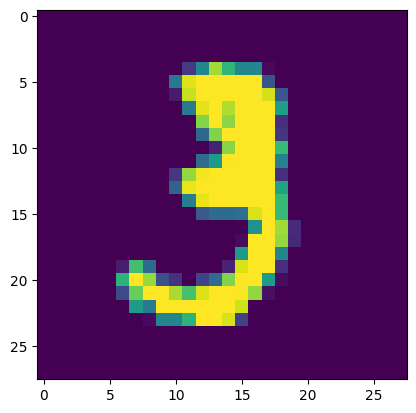

In [61]:
# displaying the image

plt.imshow(X_train[10])
plt.show()




In [62]:
#  print the corresponding label


print(Y_train[10])

3


In [63]:
# Image Labels

print(Y_train.shape, Y_test.shape)

(60000,) (10000,)


In [64]:
# unique values in Y_train
print(np.unique(Y_train))

[0 1 2 3 4 5 6 7 8 9]


In [65]:
# unique values in Y_test
print(np.unique(Y_test))

[0 1 2 3 4 5 6 7 8 9]


In [66]:
# We can use these labels as such or we can also apply One Hot encoding




In [67]:
# All the images have the same dimensions in this dataset. if not, we have to resize all the images

In [68]:
# scaling the values

X_train = X_train/255
X_test = X_test/255


print(X_train)
print(X_test)

[[[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 ...

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]]
[[[0. 0. 0

In [69]:
print(X_train[10])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [70]:
# building the neural network


# Setting up the layers of the neural network

model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid'),
])

C:\Users\USER\miniconda3\envs\nlp_course_env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [71]:
# compiling the Neural network

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy']
              )

In [72]:
# Training the neural network

model.fit(X_train, Y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9122 - loss: 0.3005
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9568 - loss: 0.1422
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9685 - loss: 0.1038
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9752 - loss: 0.0816
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9793 - loss: 0.0674
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9827 - loss: 0.0561
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9862 - loss: 0.0472
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9874 - loss: 0.0411
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9887 - loss: 0.0356
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9902 - loss: 0.0317


In [73]:
# Training data accuracy = 94.26%


In [74]:
# accuracy on test data


loss, accuracy = model.evaluate(X_test, Y_test)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9709 - loss: 0.1135


In [75]:
print(accuracy)

0.9708999991416931


In [76]:
# Test data accuracy = 94.20%


In [77]:
print(X_test.shape)

(10000, 28, 28)


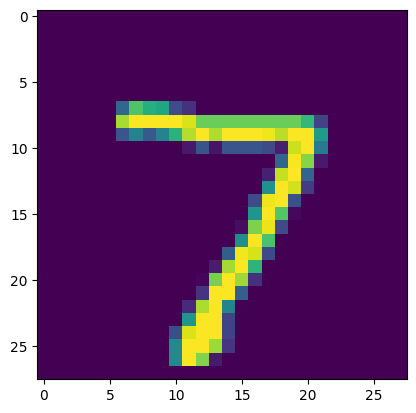

In [78]:
# first data point in X_test
plt.imshow(X_test[0])

In [79]:
print(Y_test[0])

7


In [80]:
Y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [81]:
Y_pred.shape

(10000, 10)

In [82]:
print(Y_pred[0])

[9.0894520e-02 2.4171975e-06 2.2201406e-02 9.9673355e-01 6.3982526e-09
 5.0536222e-03 1.9119257e-12 9.9999869e-01 6.0808796e-01 9.9536300e-01]


In [83]:
#  model.predict() gives the prediction probability of each class for that particular data point



In [84]:
# Converting the prediction probability to class label


label_for_first_image = np.argmax(Y_pred[0])
print(label_for_first_image)

7


In [85]:
# Converting the prediction probability to class label for all test data points


Y_pred_labels = [np.argmax(i) for i in Y_pred]
print(Y_pred_labels)

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4), np.int64(1), np.int64(4), np.int64(9), np.int64(5), np.int64(9), np.int64(0), np.int64(6), np.int64(9), np.int64(0), np.int64(1), np.int64(5), np.int64(9), np.int64(7), np.int64(3), np.int64(4), np.int64(9), np.int64(6), np.int64(6), np.int64(5), np.int64(4), np.int64(0), np.int64(7), np.int64(4), np.int64(0), np.int64(1), np.int64(3), np.int64(1), np.int64(3), np.int64(4), np.int64(7), np.int64(2), np.int64(7), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(7), np.int64(4), np.int64(2), np.int64(3), np.int64(5), np.int64(1), np.int64(2), np.int64(4), np.int64(4), np.int64(6), np.int64(3), np.int64(5), np.int64(5), np.int64(6), np.int64(0), np.int64(4), np.int64(1), np.int64(9), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(3), np.int64(7), np.int64(4), np.int64(6), np.int64(4), np.int64(3), np.int64(0), np.int64(7), np.int64(0), np.int64(2), np.int64(9), np.int64(1), np.int64(7), np.int64(3)

In [86]:
# Y_test  ---> true labels
# Y_pred_labels ----> predicted labels

In [87]:
# Building the confusion matrix

conf_mat = confusion_matrix(Y_test, Y_pred_labels)

In [88]:
print(conf_mat)

tf.Tensor(
[[ 956    0    1    2    5    1    2    1    3    9]
 [   1 1094    3    5    4    0    3    3   20    2]
 [   2    0 1002    8    3    0    1    3   11    2]
 [   0    0    1  994    1    3    0    3    4    4]
 [   0    0    3    0  968    0    4    0    1    6]
 [   3    0    0   25    3  847    3    0    9    2]
 [   5    2    2    2    4    4  935    0    4    0]
 [   1    1    6    6    0    1    0  997    2   14]
 [   6    0    2   10    1    4    1    4  942    4]
 [   1    2    0    3   14    3    0    5    7  974]], shape=(10, 10), dtype=int32)


Text(0.5, 47.7222222222222, 'Predicted Labels')

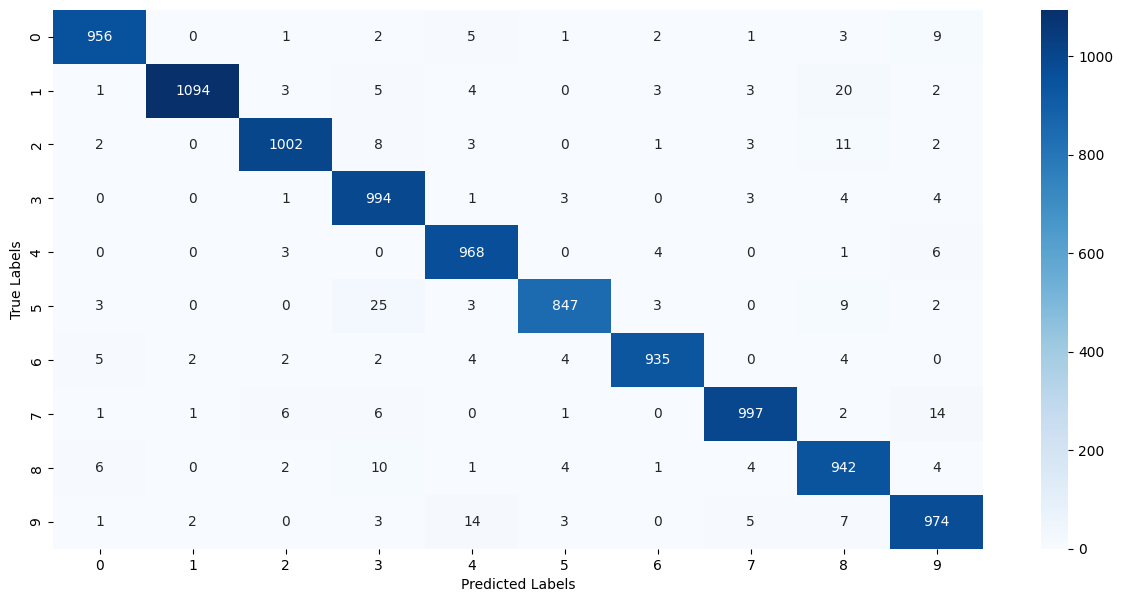

In [90]:
plt.figure(figsize=(15, 7))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
plt.ylabel('True Labels')
plt.xlabel('Predicted Labels')



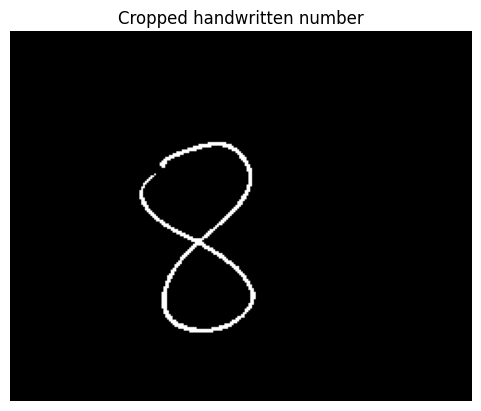

In [149]:
# Building a predictive system for the model
# a random image of a digit was saved in the project folder, this image will be loaded and predicted with the model



import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load the original photo
photo = cv2.imread("./sample_data/test_image.jpeg")

# Crop around the handwritten number.
# These coordinates are approximate for your uploaded photo.
crop = photo[360:560, 220:470]

# Convert to grayscale
gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

# Increase contrast and separate the ink from the paper
gray = cv2.GaussianBlur(gray, (3, 3), 0)
_, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

plt.imshow(binary, cmap="gray")
plt.title("Cropped handwritten number")
plt.axis("off")
plt.show()

In [150]:
def prepare_digit(binary_image):
    # Find the foreground pixels
    coords = cv2.findNonZero(binary_image)

    if coords is None:
        raise ValueError("No handwritten digit detected.")

    # Crop tightly around the digit
    x, y, w, h = cv2.boundingRect(coords)
    digit = binary_image[y:y+h, x:x+w]

    # Preserve aspect ratio and fit within 20 × 20
    scale = 20 / max(w, h)
    new_w = max(1, int(w * scale))
    new_h = max(1, int(h * scale))

    digit = cv2.resize(
        digit, (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    # Center inside a 28 × 28 black canvas
    canvas = np.zeros((28, 28), dtype=np.uint8)
    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset + new_h,
        x_offset:x_offset + new_w
    ] = digit

    # Match the MNIST normalization
    canvas = canvas.astype(np.float32) / 255.0

    return canvas

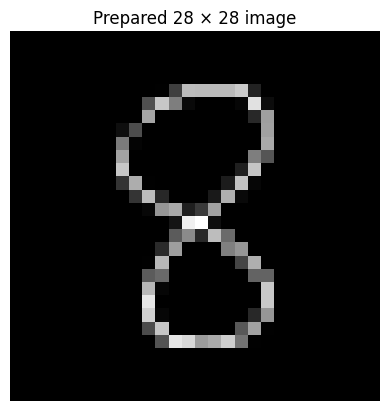

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
Predicted digit: 8


In [151]:
digit_img = prepare_digit(binary)

plt.imshow(digit_img, cmap="gray")
plt.title("Prepared 28 × 28 image")
plt.axis("off")
plt.show()

# Your model expects (batch, 28, 28)
pred = model.predict(digit_img.reshape(1, 28, 28))

print("Predicted digit:", np.argmax(pred[0]))